# Локальна перевірка правила відсікання

У фінальному ноутбуці поріг відсікання довелося перевіряти поданнями на Kaggle. Тут вирішується те саме завдання без лідерборда: правило вибирається лише за розміченими даними, а якість вимірюється на відкладених спостереженнях, яких модель не бачила.

Два незалежні експерименти:

- **Частина А** - повторювані розбиття. Імітують структуру змагання: навчання на частині даних, прогноз для відкладених 2500 спостережень, окремо рахується метрика на половині з них (як публічна частина лідерборда). Дає порівняння правил і частоту перемог одного над іншим.
- **Частина Б** - вкладена крос-валідація. Поріг підбирається всередині кожного зовнішнього фолду, метрика рахується на даних, яких не бачив ані класифікатор, ані процедура підбору порогу. Дає неупереджену підсумкову оцінку.

## 1. Пакети та дані

In [1]:
try:
    import catboost
except ImportError:
    %pip install -q catboost

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from catboost import CatBoostClassifier, Pool

In [3]:
COMPETITION = 'ml-fundamentals-and-applications-2025-07-08'

DATA_DIRS = [Path('/kaggle/input/competitions') / COMPETITION,
             Path('/kaggle/input') / COMPETITION,
             Path('../datasets')]

DATA_URL = ('https://raw.githubusercontent.com/goitacademy/'
            'MACHINE-LEARNING-NEO/main/competition/')


def data_path(filename):
    for folder in DATA_DIRS:
        if (folder / filename).exists():
            return folder / filename
    return DATA_URL + filename


data_path('final_proj_data.csv')

PosixPath('../datasets/final_proj_data.csv')

In [4]:
data = pd.read_csv(data_path('final_proj_data.csv'))
test = pd.read_csv(data_path('final_proj_test.csv'))

target = data.pop('y')

print(f'розмічених: {len(data)} | валідаційних: {len(test)}')
print(f'частка позитивного класу: {target.mean():.4f}')

розмічених: 10000 | валідаційних: 2500
частка позитивного класу: 0.1305


## 2. Підготовка ознак

Обробка така сама, як у фінальному ноутбуці: відкидаємо колонки з часткою пропусків понад 0.8 і дубльовану пару `Var200` / `Var214`, додаємо кількість пропусків у рядку.

In [5]:
na_share = data.isna().mean()

drop_cols = ['Var200', 'Var214']
cols_keep = [col for col in data.columns[na_share.lt(0.8)]
             if col not in drop_cols]


def prepare(df, cols):
    X = df[cols].copy()
    X['n_missing'] = df.isna().sum(axis=1)
    for col in X.select_dtypes(include='object').columns:
        X[col] = X[col].fillna('NA').astype(str)
    return X


X = prepare(data, cols_keep)
X_test = prepare(test, cols_keep)

cat_cols = X.select_dtypes(include='object').columns.tolist()

print(f'ознак: {X.shape[1]} (категоріальних: {len(cat_cols)})')

ознак: 75 (категоріальних: 32)


## 3. Правила відсікання, які порівнюємо

Модель у всіх випадках одна й та сама - різниця лише в тому, як із ймовірностей робиться відповідь 0/1.

| Правило | Опис |
|---|---|
| `поріг 0.5` | стандартний поріг, без підбору |
| `поріг за крос-валідацією` | аргмаксимум кривої balanced accuracy на out-of-fold прогнозах навчальної частини; перераховується для кожного розбиття |
| `поріг 0.274` | значення, підібране в основному ноутбуці за публічним балом Kaggle |
| `частка 23.1%` | позитивними позначаємо найімовірніші 23.1% спостережень - операційна точка, що відповідає 577 із 2500 |

Перше і друге правила чесні: перше нічого не підбирає, друге бачить лише навчальну частину. Третє і четверте фіксовані наперед і взяті з лідерборда - саме тому цікаво, чи витримають вони перевірку без нього.

In [6]:
PARAMS = dict(iterations=1500,
              learning_rate=0.03,
              depth=6,
              l2_leaf_reg=10,
              auto_class_weights='Balanced',
              random_seed=42,
              verbose=0)

THRESHOLDS = np.arange(0.02, 0.98, 0.001)
POS_RATE = 577 / 2500


def fit_predict(X_tr, y_tr, X_va):
    model = CatBoostClassifier(**PARAMS)
    model.fit(Pool(X_tr, y_tr, cat_features=cat_cols))
    return model.predict_proba(Pool(X_va, cat_features=cat_cols))[:, 1]


def best_threshold(y_true, proba):
    scores = pd.Series(
        [balanced_accuracy_score(y_true, (proba >= t).astype(int))
         for t in THRESHOLDS],
        index=THRESHOLDS.round(3))
    return scores.idxmax()


def by_rate(proba, rate=POS_RATE):
    k = int(round(rate * len(proba)))
    return (proba >= np.sort(proba)[::-1][k - 1]).astype(int)


RULES = {
    'поріг 0.5': lambda proba, thr_cv: (proba >= 0.5).astype(int),
    'поріг за крос-валідацією': lambda proba, thr_cv: (proba >= thr_cv).astype(int),
    'поріг 0.274': lambda proba, thr_cv: (proba >= 0.274).astype(int),
    'частка 23.1%': lambda proba, thr_cv: by_rate(proba),
}

list(RULES)

['поріг 0.5', 'поріг за крос-валідацією', 'поріг 0.274', 'частка 23.1%']

## 4. Частина А - повторювані розбиття

Кожне повторення відтворює структуру змагання: 7500 спостережень для навчання, 2500 відкладених. Поріг за крос-валідацією береться з внутрішньої 5-кратної крос-валідації на навчальній частині, тому відкладені дані на нього не впливають.

Окремо рахуємо метрику на випадковій половині відкладених (1250 рядків) - це імітація публічної частини лідерборда, яка показує, наскільки бал залежить від того, які саме спостереження туди потрапили.

In [7]:
N_REPEATS = 10
HOLDOUT = 2500

rng = np.random.RandomState(42)
records = []

for repeat in range(N_REPEATS):
    X_tr, X_ho, y_tr, y_ho = train_test_split(
        X, target, test_size=HOLDOUT, stratify=target, random_state=repeat)

    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    proba_oof = np.zeros(len(X_tr))
    for train_idx, valid_idx in inner_cv.split(X_tr, y_tr):
        proba_oof[valid_idx] = fit_predict(X_tr.iloc[train_idx],
                                           y_tr.iloc[train_idx],
                                           X_tr.iloc[valid_idx])
    threshold_cv = best_threshold(y_tr, proba_oof)

    proba_ho = fit_predict(X_tr, y_tr, X_ho)
    public = rng.permutation(HOLDOUT)[:HOLDOUT // 2]

    for name, rule in RULES.items():
        pred = rule(proba_ho, threshold_cv)
        records.append({
            'повторення': repeat,
            'правило': name,
            'поріг CV': threshold_cv,
            'BA (2500)': balanced_accuracy_score(y_ho, pred),
            'BA (1250)': balanced_accuracy_score(y_ho.iloc[public], pred[public]),
        })

    print(f'розбиття {repeat + 1}/{N_REPEATS}: поріг CV = {threshold_cv:.3f}',
          flush=True)

results = pd.DataFrame(records)
results.head()

розбиття 1/10: поріг CV = 0.288


розбиття 2/10: поріг CV = 0.296


розбиття 3/10: поріг CV = 0.271


розбиття 4/10: поріг CV = 0.239


розбиття 5/10: поріг CV = 0.303


...

розбиття 7/10: поріг CV = 0.226


розбиття 8/10: поріг CV = 0.294


розбиття 9/10: поріг CV = 0.313


розбиття 10/10: поріг CV = 0.223


,повторення,правило,поріг CV,BA (2500),BA (1250)
0,0,поріг 0.5,0.288,0.893032,0.891949
1,0,поріг за крос-валідацією,0.288,0.893040,0.892459
2,0,поріг 0.274,0.288,0.890740,0.890623
3,0,частка 23.1%,0.288,0.889360,0.889704
4,1,поріг 0.5,0.296,0.880379,0.873104


### Порівняння правил

In [8]:
summary = (results
           .groupby('правило')[['BA (2500)', 'BA (1250)']]
           .agg(['mean', 'std'])
           .round(4)
           .sort_values(('BA (2500)', 'mean'), ascending=False))

summary

BA (2500)         BA (1250)        
                              mean     std      mean     std
правило                                                     
частка 23.1%                0.8948  0.0085    0.8980  0.0088
поріг за крос-валідацією    0.8940  0.0092    0.8953  0.0089
поріг 0.274                 0.8934  0.0083    0.8953  0.0083
поріг 0.5                   0.8805  0.0091    0.8826  0.0154

Стовпець `BA (2500)` - оцінка якості правила, `BA (1250)` - те саме на половині спостережень. Стандартне відхилення другого стовпця показує, наскільки публічний бал змагання залежить від випадковості вибірки, а не від моделі.

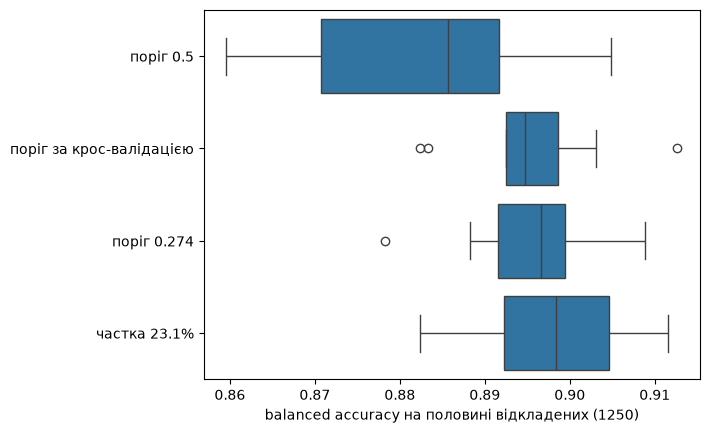

In [9]:
ax = sns.boxplot(results, x='BA (1250)', y='правило')
ax.set(xlabel='balanced accuracy на половині відкладених (1250)', ylabel='')

plt.show()

### Як часто одне правило перемагає інше

Середні значення близькі, тому корисніше подивитись, у скількох розбиттях із 10 правило з рядка виявилось кращим за правило зі стовпця.

In [10]:
pivot = results.pivot(index='повторення', columns='правило', values='BA (2500)')

wins = pd.DataFrame(
    [[(pivot[a] > pivot[b]).sum() if a != b else 0 for b in pivot.columns]
     for a in pivot.columns],
    index=pivot.columns, columns=pivot.columns)

wins

правило,поріг 0.274,поріг 0.5,поріг за крос-валідацією,частка 23.1%
правило,,,,
поріг 0.274,0,9,3,3
поріг 0.5,1,0,0,1
поріг за крос-валідацією,7,10,0,4
частка 23.1%,7,9,6,0


### Стабільність порогу

поріг за крос-валідацією: від 0.223 до 0.379, медіана 0.291


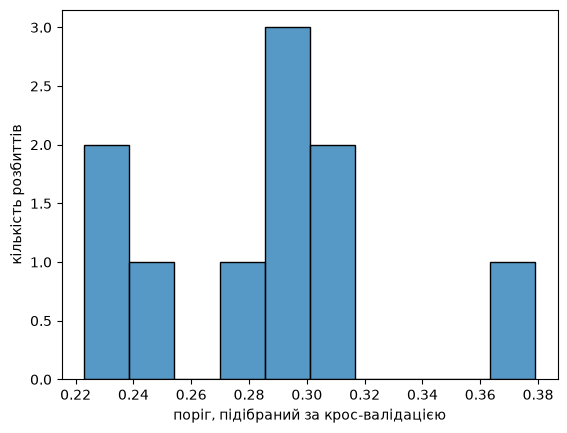

In [11]:
thr = results.groupby('повторення')['поріг CV'].first()

print(f'поріг за крос-валідацією: від {thr.min():.3f} до {thr.max():.3f}, '
      f'медіана {thr.median():.3f}')

ax = sns.histplot(thr, bins=10)
ax.set(xlabel='поріг, підібраний за крос-валідацією', ylabel='кількість розбиттів')

plt.show()

## 5. Частина Б - вкладена крос-валідація

Тут використовуються всі 10 000 розмічених спостережень. На кожному з п'яти зовнішніх фолдів поріг підбирається лише за внутрішньою крос-валідацією, а метрика рахується на відкладеному фолді. Отримане значення не містить оптимізму від підбору порогу на тих самих прогнозах.

In [12]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

nested = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, target), start=1):
    X_tr, y_tr = X.iloc[train_idx], target.iloc[train_idx]
    X_te, y_te = X.iloc[test_idx], target.iloc[test_idx]

    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    proba_oof = np.zeros(len(X_tr))
    for a, b in inner_cv.split(X_tr, y_tr):
        proba_oof[b] = fit_predict(X_tr.iloc[a], y_tr.iloc[a], X_tr.iloc[b])
    threshold_cv = best_threshold(y_tr, proba_oof)

    proba_te = fit_predict(X_tr, y_tr, X_te)
    score = balanced_accuracy_score(y_te, (proba_te >= threshold_cv).astype(int))
    nested.append({'фолд': fold, 'поріг': threshold_cv, 'BA': score})

    print(f'фолд {fold}: поріг {threshold_cv:.3f} | BA {score:.4f}', flush=True)

nested = pd.DataFrame(nested)

print(f'\nвкладена крос-валідація: {nested["BA"].mean():.4f} '
      f'± {nested["BA"].std():.4f}')

фолд 1: поріг 0.310 | BA 0.9140


фолд 2: поріг 0.299 | BA 0.8831


фолд 3: поріг 0.361 | BA 0.8963


фолд 4: поріг 0.227 | BA 0.8934


фолд 5: поріг 0.299 | BA 0.8936



вкладена крос-валідація: 0.8961 ± 0.0112


## 6. Прогноз за правилом, обраним локально

Фінальну модель навчаємо на всіх розмічених даних і застосовуємо те правило, яке виявилось найкращим у частині А.

In [13]:
best_rule = summary[('BA (2500)', 'mean')].idxmax()

print(f'найкраще правило за частиною А: {best_rule}')

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba_cv = np.zeros(len(X))
for train_idx, valid_idx in inner_cv.split(X, target):
    proba_cv[valid_idx] = fit_predict(X.iloc[train_idx],
                                      target.iloc[train_idx],
                                      X.iloc[valid_idx])

threshold_cv = best_threshold(target, proba_cv)

print(f'поріг за крос-валідацією на всіх даних: {threshold_cv:.3f}')
print(f'ROC AUC: {roc_auc_score(target, proba_cv):.4f}')

найкраще правило за частиною А: частка 23.1%


поріг за крос-валідацією на всіх даних: 0.331
ROC AUC: 0.9637


In [14]:
model_full = CatBoostClassifier(**PARAMS)
model_full.fit(Pool(X, target, cat_features=cat_cols))

proba_test = model_full.predict_proba(
    Pool(X_test, cat_features=cat_cols))[:, 1]

pred_test = RULES[best_rule](proba_test, threshold_cv)

submission = pd.DataFrame({'index': test.index, 'y': pred_test})
submission.to_csv('submission_local.csv', index=False)

print(f'позитивних: {pred_test.sum()} із {len(pred_test)} '
      f'({pred_test.mean():.1%})')

submission.head()

позитивних: 577 із 2500 (23.1%)


,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


## 7. Висновки

PLACEHOLDER